In [2]:
from convokit import Corpus, download

In [3]:
corpus = Corpus(
    filename=download("conversations-gone-awry-corpus")
)

Dataset already exists at C:\Users\Prarthana\.convokit\saved-corpora\conversations-gone-awry-corpus


In [4]:
corpus.print_summary_stats()

Number of Speakers: 8069
Number of Utterances: 30021
Number of Conversations: 4188


In [5]:
convo = next(corpus.iter_conversations())

print(convo.meta)

ConvoKitMeta({'page_title': 'User talk:2005', 'page_id': 1003212, 'pair_id': '143890867.11926.11926', 'conversation_has_personal_attack': False, 'verified': True, 'pair_verified': True, 'annotation_year': '2018', 'split': 'train'})


In [6]:
for utt in convo.iter_utterances():
    print(
        utt.speaker.id,
        "|",
        utt.timestamp,
        "|",
        utt.text[:100]
    )

Sirex98 | 1185295934.0 | == [WIKI_LINK: WP:COMMONNAME] ==

Sirex98 | 1185277934.0 | I notice that earier that  moved wiki_link to Bill Chen citing wiki_link , then you reverted this ch
2005 | 1185310317.0 | Chen was known in the poker world as "William" for years before he became commonly known as "Bill". 
Sirex98 | 1185316241.0 | I see what you saying I just read his pokerstars profile, It struck me when I saw the change because


In [7]:
for utt in convo.iter_utterances():
    print("ID:", utt.id)
    print("Speaker:", utt.speaker.id)
    print("Reply to:", utt.reply_to)
    print("Timestamp:", utt.timestamp)
    print("Text:", utt.text)
    print("Metadata:", utt.meta)
    print("-" * 80)

ID: 146743638.12652.12652
Speaker: Sirex98
Reply to: None
Timestamp: 1185295934.0
Text: == [WIKI_LINK: WP:COMMONNAME] ==

Metadata: ConvoKitMeta({'is_section_header': True, 'comment_has_personal_attack': False, 'toxicity': 0, 'parsed': [{'rt': 3, 'toks': [{'tok': '=', 'tag': 'NFP', 'dep': 'punct', 'up': 3, 'dn': []}, {'tok': '=', 'tag': 'LS', 'dep': 'punct', 'up': 3, 'dn': []}, {'tok': '[', 'tag': '-LRB-', 'dep': 'punct', 'up': 3, 'dn': []}, {'tok': 'WIKI_LINK', 'tag': 'JJ', 'dep': 'ROOT', 'dn': [0, 1, 2, 4]}, {'tok': ':', 'tag': ':', 'dep': 'punct', 'up': 3, 'dn': []}]}, {'rt': 0, 'toks': [{'tok': 'WP', 'tag': 'NNP', 'dep': 'ROOT', 'dn': [1, 2, 5]}, {'tok': ':', 'tag': ':', 'dep': 'punct', 'up': 0, 'dn': []}, {'tok': 'COMMONNAME', 'tag': 'NNPS', 'dep': 'appos', 'up': 0, 'dn': [3]}, {'tok': ']', 'tag': '-RRB-', 'dep': 'punct', 'up': 2, 'dn': []}, {'tok': '=', 'tag': 'SYM', 'dep': 'punct', 'up': 5, 'dn': []}, {'tok': '=', 'tag': 'SYM', 'dep': 'punct', 'up': 0, 'dn': [4, 6]}, {'tok': '\n

In [8]:
for i, convo in enumerate(corpus.iter_conversations()):
    print("Conversation:", convo.id)
    print("Metadata:", convo.meta)
    print("-" * 80)

    if i == 9:
        break

Conversation: 146743638.12652.12652
Metadata: ConvoKitMeta({'page_title': 'User talk:2005', 'page_id': 1003212, 'pair_id': '143890867.11926.11926', 'conversation_has_personal_attack': False, 'verified': True, 'pair_verified': True, 'annotation_year': '2018', 'split': 'train'})
--------------------------------------------------------------------------------
Conversation: 143890867.11926.11926
Metadata: ConvoKitMeta({'page_title': 'User talk:2005', 'page_id': 1003212, 'pair_id': '146743638.12652.12652', 'conversation_has_personal_attack': True, 'verified': True, 'pair_verified': True, 'annotation_year': '2018', 'split': 'train'})
--------------------------------------------------------------------------------
Conversation: 127296808.516.516
Metadata: ConvoKitMeta({'page_title': 'User talk:Billzilla', 'page_id': 10051321, 'pair_id': '144643838.1236.1236', 'conversation_has_personal_attack': False, 'verified': True, 'pair_verified': True, 'annotation_year': '2018', 'split': 'train'})
-----

In [9]:
labels = []

for convo in corpus.iter_conversations():
    labels.append(
        convo.meta["conversation_has_personal_attack"]
    )

from collections import Counter

Counter(labels)

Counter({False: 2094, True: 2094})

In [10]:
counts = Counter(labels)

total = sum(counts.values())

for label, count in counts.items():
    percentage = (count / total) * 100

    print(
        label,
        ":",
        count,
        f"({percentage:.2f}%)"
    )

False : 2094 (50.00%)
True : 2094 (50.00%)


### Dataset Class Balance

Total conversations: XXXXX

Personal-attack / derailment:
- True: 2094
- False: 2094

Class percentages:
- True: 50%
- False: 50%

In [12]:
conversation_lengths = []

for convo in corpus.iter_conversations():

    length = sum(
        1 for _ in convo.iter_utterances()
    )

    conversation_lengths.append(length)

In [13]:
print("Minimum:", min(conversation_lengths))
print("Maximum:", max(conversation_lengths))
print(
    "Average:",
    sum(conversation_lengths) / len(conversation_lengths)
)

Minimum: 3
Maximum: 20
Average: 7.168338108882521


In [14]:
import numpy as np

print(
    "Median:",
    np.median(conversation_lengths)
)

Median: 7.0


In [15]:
import matplotlib.pyplot as plt

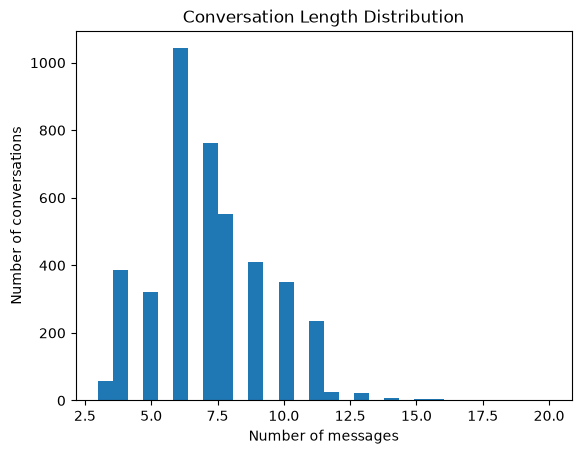

In [16]:
plt.hist(
    conversation_lengths,
    bins=30
)

plt.xlabel("Number of messages")
plt.ylabel("Number of conversations")
plt.title("Conversation Length Distribution")

plt.show()

In [17]:
def print_conversation(convo):
    print("=" * 100)
    print("Conversation ID:", convo.id)
    print("Conversation metadata:", convo.meta)
    print("=" * 100)

    for i, utt in enumerate(convo.iter_utterances()):
        print(
            f"[{i}] {utt.speaker.id}: {utt.text}"
        )

    print("=" * 100)

In [18]:
derailing = []

for convo in corpus.iter_conversations():

    if convo.meta["conversation_has_personal_attack"]:
        derailing.append(convo)

print(
    "Derailing conversations:",
    len(derailing)
)

Derailing conversations: 2094


In [19]:
print_conversation(derailing[0])

Conversation ID: 143890867.11926.11926
Conversation metadata: ConvoKitMeta({'page_title': 'User talk:2005', 'page_id': 1003212, 'pair_id': '146743638.12652.12652', 'conversation_has_personal_attack': True, 'verified': True, 'pair_verified': True, 'annotation_year': '2018', 'split': 'train'})
[0] WilyD: ==List of slang terms for poker hands==

[1] WilyD: No more than two editors advocated deletion.  Greatestrowerever and maybe Kymacpherson.  That's not a clear consensus for deletion.  Cheers, 
[2] 2005: In the future please don't close Afds when you don't have the courtesy of reading the comments.  All comments favored deletion except two.  Please don't be so careless in the future. 
[3] WilyD: That simply isn't true.  If you read the comments, you'll find it's actually 2 keep, 4 transwiki, 2 delete (more or less).  The ''comments'' favour no consensus/transwiki.  The "votes" favour delete, but voting is evil, of course... 
[4] WilyD: Somehow, I suspect you may wish to participate in wi